In [2]:
import scanpy as sc
adata_T = sc.read("./h5ad/adata_T.h5ad")
adata_B = sc.read("./h5ad/adata_B.h5ad")
adata_myeloid = sc.read("./h5ad/adata_myeloid.h5ad")
adata_fibroblast = sc.read("./h5ad/adata_fibroblast.h5ad")

In [10]:
merged = sc.concat(
    [adata_T, adata_B, adata_myeloid, adata_fibroblast],
    join="inner",
    label="type",
    keys=["T", "B", "myeloid", "fibroblast"]
)

In [11]:
H_poor = ["H-nS01","H-nS09","H-nS10"]
H_good = ["H-nS03","H-nS06","H-nS07","H-nS08"]
Q_poor = ["Q-nS01","Q-nS02"]
Q_good = ["Q-nS03","Q-nS04"]

In [13]:
sc.write("./h5ad/H_poor_sub.h5ad",merged[merged.obs["batch"].isin(H_poor)])
sc.write("./h5ad/Q_poor_sub.h5ad",merged[merged.obs["batch"].isin(Q_poor)])
sc.write("./h5ad/H_good_sub.h5ad",merged[merged.obs["batch"].isin(H_good)])
sc.write("./h5ad/Q_good_sub.h5ad",merged[merged.obs["batch"].isin(Q_good)])

In [1]:
import cellphonedb as cpd
from cellphonedb.src.core.methods import cpdb_statistical_analysis_method
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scanpy as sc
import numpy as np
import anndata as ad
import ktplotspy as kpy
import os



for name in ['H_poor_sub','H_good_sub','Q_poor_sub','Q_good_sub']:
    adata = sc.read('./h5ad/'+name+".h5ad", var_names='gene_symbols')
    # Remove rows with gene IDs starting with 'ENSG'
    adata = adata[:,~adata.var_names.str.startswith('ENSG')]

    # Prepare required input files
    # Raw count matrix
    counts_df = pd.DataFrame(adata.X.T.todense(), index=adata.var_names, columns=adata.obs_names)
    counts_df.to_csv('counts_matrix.csv')

    # Metadata file (requires cell type annotation in adata.obs['celltype'])
    meta_data = pd.DataFrame({'Cell': adata.obs_names, 'cell_type': adata.obs['celltype']})
    meta_data.to_csv('meta_data.csv', index=False)

    # Run CellPhoneDB
    cpdb_results = cpdb_statistical_analysis_method.call(
        meta_file_path='meta_data.csv',
        counts_file_path='counts_matrix.csv',
        cpdb_file_path='cellphonedb.zip',  # 这就是你的 cpdb_file_path
        counts_data = 'hgnc_symbol',
        output_path = "./res",
        subsampling=False,
        score_interactions = True,
    )

    means_df = cpdb_results['means']

    means_df.to_csv("./table/"+name+'_mean.csv', index=False)

    means_sig_df = cpdb_results['significant_means']
    means_sig_df.to_csv("./table/"+name+'_significant_means.csv', index=False)

Reading user files...
The following user files were loaded successfully:
counts_matrix.csv
meta_data.csv
[ ][CORE][24/10/26-19:20:52][INFO] [Cluster Statistical Analysis] Threshold:0.1 Iterations:1000 Debug-seed:-1 Threads:4 Precision:3
[ ][CORE][24/10/26-19:20:54][INFO] Running Real Analysis
[ ][CORE][24/10/26-19:20:54][INFO] Running Statistical Analysis


100%|███████████████████████████████████████████████████████████████████████████████| 1000/1000 [03:51<00:00,  4.31it/s]

[ ][CORE][24/10/26-19:24:46][INFO] Building Pvalues result


[ ][CORE][24/10/26-19:24:51][INFO] Building results
[ ][CORE][24/10/26-19:24:51][INFO] Scoring interactions: Filtering genes per cell type..


100%|██████████████████████████████████████████████████████████████████████████████████| 46/46 [00:00<00:00, 181.22it/s]

...

[ ][CORE][24/10/26-20:22:42][INFO] Scoring interactions: Calculating mean expression of each gene per group/cell type..



100%|██████████████████████████████████████████████████████████████████████████████████| 46/46 [00:00<00:00, 408.66it/s]


[ ][CORE][24/10/26-20:22:43][INFO] Scoring interactions: Calculating scores for all interactions and cell types..


100%|███████████████████████████████████████████████████████████████████████████████| 2116/2116 [07:17<00:00,  4.83it/s]


Saved deconvoluted to ./res/statistical_analysis_deconvoluted_10_24_2026_203006.txt
Saved deconvoluted_percents to ./res/statistical_analysis_deconvoluted_percents_10_24_2026_203006.txt
Saved means to ./res/statistical_analysis_means_10_24_2026_203006.txt
Saved pvalues to ./res/statistical_analysis_pvalues_10_24_2026_203006.txt
Saved significant_means to ./res/statistical_analysis_significant_means_10_24_2026_203006.txt
Saved interaction_scores to ./res/statistical_analysis_interaction_scores_10_24_2026_203006.txt


/tmp/ipykernel_772171/4231073330.py:18: DtypeWarning:

Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.



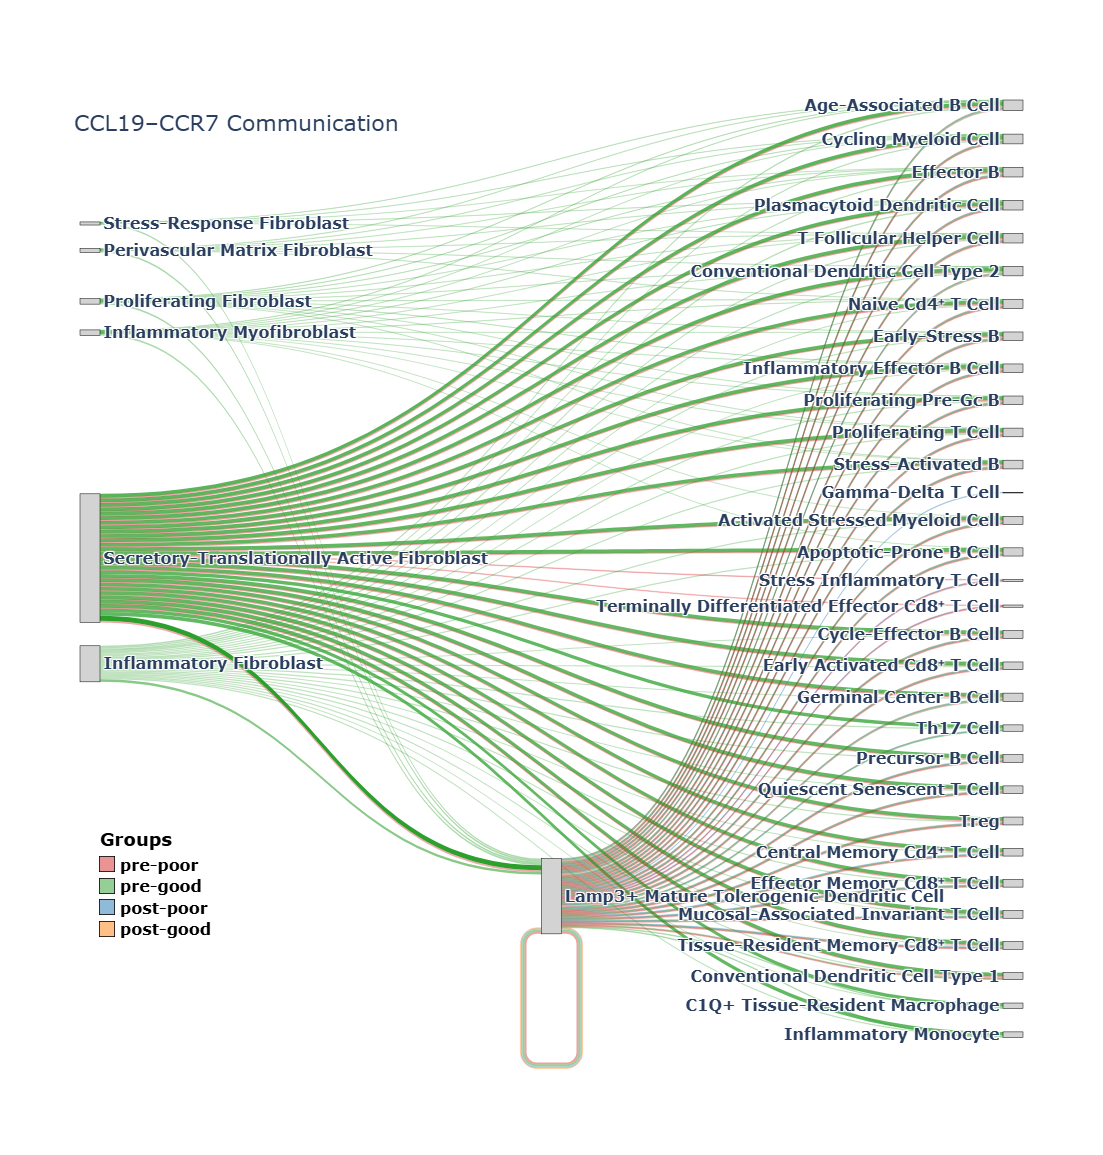

In [6]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# Assume adata_T, adata_B, adata_fibroblast, adata_myeloid are already defined
nodes = cells = list(set(adata_T.obs["celltype"])) + \
         list(set(adata_B.obs["celltype"])) + \
         list(set(adata_fibroblast.obs["celltype"])) + \
         list(set(adata_myeloid.obs["celltype"]))

# Deduplicate and sort for stable ordering
nodes = sorted(list(set(nodes)))

files = ["H_good_sub", "H_poor_sub", "Q_good_sub", "Q_poor_sub"]
cpdbdata = np.zeros((len(nodes), len(nodes), 4))

for i, f in enumerate(files):
    df = pd.read_csv('./table/' + f + '_significant_means.csv')
    row = df[df['interacting_pair'] == "CCL19_CCR7"]
    for j, n1 in enumerate(nodes):
        for k, n2 in enumerate(nodes):
            try:
                cpdbdata[j, k, i] = 0 if np.isnan(row.iloc[0][f"{n1}|{n2}"]) else row.iloc[0][f"{n1}|{n2}"]
            except KeyError:
                cpdbdata[j, k, i] = 0

# Filter active nodes (those involved in communication)
total_in = np.sum(np.sum(cpdbdata, axis=2), axis=0)
total_out = np.sum(np.sum(cpdbdata, axis=2), axis=1)

nodes1 = set(np.array(nodes)[total_in > 0])   # Receivers
nodes2 = set(np.array(nodes)[total_out > 0])  # Senders

all_nodes = sorted(list(nodes1 | nodes2))
node_to_idx = {node: idx for idx, node in enumerate(all_nodes)}

# ==========================================
# Core change: define the node name formatting function
# ==========================================
def format_node_name(name):
    # 1. Special replacement: replace Regulatory with Helper (still plural at this point)
    if "T Follicular Regulatory Cell" in name:
        name = name.replace("T Follicular Regulatory Cell", "T Follicular Helper Cell")

    # 2. Remove trailing 's' (handle plural form)
    # Use rstrip('s') to strip all trailing 's', or name[:-1] if only one 's' is expected.
    # Here we assume there is at most one trailing 's' to remove.
    if name.endswith('s'):
        name = name.rstrip('s')

    # 3. Title case
    # Note: title() also capitalizes words inside parentheses, which is usually desired.
    return name.title()

# Create mapping: old name -> formatted name
node_name_map = {old_name: format_node_name(old_name) for old_name in all_nodes}

# Node coloring: main color vs auxiliary color
main_colors = ["#D3D3D3"]

aux_colors = ["#D3D3D3"] * 32

# Stable sorting to ensure consistent colors
nodes1_only = sorted([n for n in nodes1 if n not in nodes2])
nodes2_sorted = sorted(nodes2)

node_colors = []
for node in all_nodes:
    if node in nodes2:
        idx = nodes2_sorted.index(node) % len(main_colors)
        node_colors.append(main_colors[idx])
    else:
        idx = nodes1_only.index(node) % len(aux_colors)
        node_colors.append(aux_colors[idx])

# Define base colors for the 4 conditions
base_colors = [
    "rgb(255, 127, 14)",   # H-poor
    "rgb(31, 119, 180)",   # H-good
    "rgb(44, 160, 44)",    # Q-good
    "rgb(214, 39, 40)"     # Q-poor
]

links = {'source': [], 'target': [], 'value': [], 'color': []}
max_val = np.max(cpdbdata)

coef = 5
for i in range(4):
    for j, n1 in enumerate(nodes):
        for k, n2 in enumerate(nodes):
            val = cpdbdata[j, k, i]
            if val > 0:
                if n1 in node_to_idx and n2 in node_to_idx:
                    src = node_to_idx[n1]
                    tgt = node_to_idx[n2]
                    alpha = min(val / max_val * 0.9 + 0.1, 1)
                    color_with_alpha = f"rgba({base_colors[i][4:-1]}, {alpha})"
                    links['source'].append(src)
                    links['target'].append(tgt)
                    links['value'].append(val*coef)
                    links['color'].append(color_with_alpha)

display_labels = [node_name_map[node] for node in all_nodes]

# Create Sankey diagram
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=display_labels,  # Use the variable directly; no list comprehension here
        color=node_colors,
    ),
    link=dict(
        source=links['source'],
        target=links['target'],
        value=links['value'],
        color=links['color']
    ),
    textfont=dict(size=16, weight="bold")
)])  # Closing order: go.Sankey() -> data list ] -> Figure()

fig.update_layout(
    title_text="CCL19–CCR7 Communication",
    font_size=16,
    width=1200,
    height=max(600, 30 * len(all_nodes)),
    title_y=0.9,
    title_x=0.067
)

# ==============================
# Legend section (unchanged; layout adjustments optional)
# ==============================
legend_x = 0.02
legend_y = 0.15
line_spacing = 0.022

new_labels = ["post-good", "post-poor", "pre-good", "pre-poor"]

def parse_rgb(rgb_str):
    return tuple(map(int, rgb_str[4:-1].split(", ")))

base_colors_rgb = [parse_rgb(c) for c in base_colors]
legend_items = list(zip(new_labels, base_colors_rgb))

title_y = legend_y + len(legend_items) * line_spacing - 0.008

fig.add_annotation(
    x=legend_x,
    y=title_y,
    xref="paper",
    yref="paper",
    xanchor="left",
    yanchor="bottom",
    text="<b>Groups</b>",
    showarrow=False,
    font=dict(size=18, color="black", weight="bold"),
    bgcolor="white",
    bordercolor="black",
    borderwidth=0,
)

for i, (label, rgb) in enumerate(legend_items):
    y_offset = legend_y + i * line_spacing
    r, g, b = rgb
    fig.add_annotation(
        x=legend_x,
        y=y_offset,
        xref="paper",
        yref="paper",
        xanchor="left",
        yanchor="middle",
        text="",
        showarrow=False,
        bgcolor=f"rgba({r},{g},{b},0.5)",
        bordercolor="black",
        borderwidth=0.8,
        width=12,
        height=12,
    )
    fig.add_annotation(
        x=legend_x + 0.02,
        y=y_offset,
        xref="paper",
        yref="paper",
        xanchor="left",
        yanchor="middle",
        text=label,
        showarrow=False,
        font=dict(size=16, color="black", weight="bold"),
        align="left"
    )
fig.show()